# Lesson 2: Can we trust the sales table?

<p class="lead">
Before comparing anything, find out exactly what the retail table contains: what a row is, how the setup cell prepared it, which columns can be added up, and how to count orders correctly.
</p>

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Aayush181509/AnalyticsLecture/blob/main/notebooks/02_trust_the_sales_table.ipynb)

Open this notebook in Google Colab with the button above, then run each cell from top to bottom with **Shift + Enter**. Save your own copy with **File → Save a copy in Drive**.

---

## The business decision

The retail head now asks:

> *"Before you show me any chart, can I trust these numbers? How many orders did we actually have?"*

A wrong count at this stage spoils every later chart. This lesson is about building trust in the data.

> **About the data**
>
> The Superstore sample describes a **fictitious** company. Sales and Profit are in **source monetary units**: the file does not state a currency, so we never add a currency symbol.

---

## What you will be able to do

By the end of this lesson you will be able to:

1. Explain what the setup cell's `load_orders()` does, step by step.
2. State the **grain** of the table: what one row represents.
3. Tell which columns are identifiers, categories, dates or amounts.
4. Count **orders** correctly with `nunique()`.
5. Explain what the returns flag does and does not tell you.
6. Check one order by hand.
7. Record what you changed in a short **preparation log**.

**Evidence you keep:** a grain statement, a short quality checklist, a preparation log and one checked order.

Before you start, complete [Lesson 1](01_decision_to_evidence.md) and have your evidence log open.

---

## Part 1: Load the data

Run the setup cell first, exactly as in Lesson 1.

In [1]:
# Course data setup. Run this cell first; you do not need to understand it yet.
# It downloads the Superstore sample from Tableau's website, checks it is the
# exact version this course was written for, and prepares the order-lines table.
import hashlib
import os
import urllib.request

import matplotlib.pyplot as plt
import pandas as pd

SOURCE_URL = "https://public.tableau.com/app/sample-data/sample_-_superstore.xls"
EXPECTED_SHA256 = "5045ed4fec49cae2cc0dfc5ab0d204ba09efa767fe00c996822499e8cc42fbbd"
SOURCE_FILE = os.environ.get("COURSE_XLS_PATH", "sample_-_superstore.xls")

try:
    import xlrd  # noqa: F401  (needed to read .xls files)
except ImportError:
    import subprocess
    import sys

    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "xlrd"])

if not os.path.exists(SOURCE_FILE):
    urllib.request.urlretrieve(SOURCE_URL, SOURCE_FILE)

with open(SOURCE_FILE, "rb") as f:
    digest = hashlib.sha256(f.read()).hexdigest()
if digest != EXPECTED_SHA256:
    print("WARNING: Tableau has changed this sample file since the course was written.")
    print("Your numbers will differ from the lesson. Ask your facilitator for the course copy.")


def load_orders():
    """Return one row per order line, orders placed 2023-01-01 to 2025-12-31."""
    raw = pd.read_excel(SOURCE_FILE, sheet_name="Orders")
    returns = pd.read_excel(SOURCE_FILE, sheet_name="Returns")

    # Orders with more than one Customer ID (a known data issue), found before filtering.
    ids_per_order = raw.groupby("Order ID")["Customer ID"].nunique()
    conflict_orders = set(ids_per_order[ids_per_order > 1].index)

    in_scope = (raw["Order Date"] >= "2023-01-01") & (raw["Order Date"] < "2026-01-01")
    df = raw.loc[in_scope].copy()

    df = df.rename(columns={
        "Row ID": "row_id", "Order ID": "order_id", "Order Date": "order_date",
        "Ship Date": "ship_date", "Ship Mode": "ship_mode", "Customer ID": "customer_id",
        "Segment": "segment", "Country/Region": "country_region", "Region": "region",
        "Category": "category", "Sub-Category": "sub_category", "Product ID": "product_id",
        "Product Name": "product_name", "Sales": "sales", "Quantity": "quantity",
        "Discount": "discount", "Profit": "profit",
    })
    df["returned_order_flag"] = df["order_id"].isin(set(returns["Order ID"])).astype(int)
    df["customer_order_conflict"] = df["order_id"].isin(conflict_orders).astype(int)
    df["customer_analysis_eligible"] = 1 - df["customer_order_conflict"]
    df["order_to_ship_days"] = (df["ship_date"] - df["order_date"]).dt.days
    df["order_month"] = df["order_date"].dt.to_period("M").dt.to_timestamp()

    columns = [
        "row_id", "order_id", "order_date", "ship_date", "ship_mode", "customer_id",
        "segment", "country_region", "region", "category", "sub_category", "product_id",
        "product_name", "sales", "quantity", "discount", "profit", "returned_order_flag",
        "customer_analysis_eligible", "customer_order_conflict", "order_to_ship_days",
        "order_month",
    ]
    return df[columns].sort_values("row_id").reset_index(drop=True)


pd.set_option("display.float_format", "{:,.2f}".format)
plt.rcParams.update({
    "figure.figsize": (8, 4),
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "axes.axisbelow": True,
    "grid.color": "#e6e5e1",
    "axes.prop_cycle": plt.cycler(color=["#2a78d6", "#eb6834", "#1baf7a"]),
    "axes.titleweight": "bold",
    "axes.titlelocation": "left",
})
print("Setup complete.")

Setup complete.


In [2]:
df = load_orders()
print("Rows, columns:", df.shape)

Rows, columns: (6815, 22)


---

## Part 2: What `load_orders()` does

In Lesson 1 you used `load_orders()` without looking inside. Now we open it up. You do not need to memorise this code; you need to know **what was changed** between the original file and `df`, so you can explain your numbers.

The function does seven things:

| Step | What happens | Why |
|---|---|---|
| 1 | Reads the **Orders** and **Returns** sheets from the Excel file | These are the raw tables |
| 2 | Finds orders that have more than one Customer ID | A known data issue, flagged before filtering |
| 3 | Keeps orders placed from **2023-01-01 to 2025-12-31** | Gives the course a fixed, complete period |
| 4 | Renames columns to short lowercase names | Easier to type: `order_id` instead of `"Order ID"` |
| 5 | Adds `returned_order_flag` | Marks orders on the returns list |
| 6 | Adds `customer_order_conflict` and `customer_analysis_eligible` | Marks the customer-ID issue from step 2 |
| 7 | Adds `order_to_ship_days` and `order_month`, then keeps 22 columns sorted by `row_id` | Handy derived columns |

The cells below repeat each step on its own so you can see the effect.

### Step 1: Read the raw sheets

`SOURCE_FILE` is the Excel file the setup cell downloaded. `pd.read_excel` reads one sheet into a DataFrame.

In [3]:
raw = pd.read_excel(SOURCE_FILE, sheet_name="Orders")
returns = pd.read_excel(SOURCE_FILE, sheet_name="Returns")

print("Raw Orders sheet, rows and columns:", raw.shape)
print("Returns sheet, rows and columns:   ", returns.shape)
print("Order dates in the raw file:", raw["Order Date"].min().date(), "to", raw["Order Date"].max().date())

Raw Orders sheet, rows and columns: (10194, 21)
Returns sheet, rows and columns:    (296, 2)
Order dates in the raw file: 2023-01-03 to 2026-12-30


The raw file has more rows than `df`, and its dates run further. The Returns sheet is just a list of order IDs:

In [4]:
returns.head(3)

,Order ID,Returned
0,US-2023-100762,Yes
1,US-2023-100867,Yes
2,US-2023-102652,Yes


### Step 2: Find orders with more than one customer

Every order should belong to one customer. The code counts the different Customer IDs inside each order and keeps the orders where that count is above 1. This is done on the **whole raw file**, before any filtering, so no conflict is hidden by the date filter.

In [5]:
ids_per_order = raw.groupby("Order ID")["Customer ID"].nunique()
conflict_orders = set(ids_per_order[ids_per_order > 1].index)
conflict_orders

{'CA-2025-121465', 'CA-2026-130494'}

### Step 3: Keep orders placed 2023 to 2025

The filter keeps rows whose **Order Date** is on or after 1 January 2023 and before 1 January 2026. It looks at the order date only.

In [6]:
in_scope = (raw["Order Date"] >= "2023-01-01") & (raw["Order Date"] < "2026-01-01")
print("Rows kept:   ", in_scope.sum())
print("Rows dropped:", (~in_scope).sum())

Rows kept:    6815
Rows dropped: 3379


The ship date is **not** filtered. An order placed late in 2025 may ship in early 2026, and it stays in, because the order date defines the period:

In [7]:
print("Lines in df that shipped in 2026:", (df["ship_date"] >= "2026-01-01").sum())

Lines in df that shipped in 2026: 34


### Step 4: Rename columns

`rename` swaps the original names (with spaces and capitals) for short names. Four raw columns are not kept at all, because the course does not need them:

In [8]:
kept_raw = ["Row ID", "Order ID", "Order Date", "Ship Date", "Ship Mode", "Customer ID",
            "Segment", "Country/Region", "Region", "Category", "Sub-Category", "Product ID",
            "Product Name", "Sales", "Quantity", "Discount", "Profit"]
[col for col in raw.columns if col not in kept_raw]

['Customer Name', 'City', 'State/Province', 'Postal Code']

### Step 5: The returns flag

`isin` asks, for each row, "is this order ID on the returns list?". The answer `True`/`False` is turned into `1`/`0`. A three-line order on the list gets a `1` on **all three lines**.

### Step 6: The customer-conflict flags

The same `isin` trick marks every line of a conflicted order with `customer_order_conflict = 1`. `customer_analysis_eligible` is the opposite (`1 - conflict`). These lines stay in all Sales and order counts; they are left out only when we later analyse individual customers.

In [9]:
df.groupby("customer_order_conflict")["order_id"].nunique()

customer_order_conflict
0    3387
1       1
Name: order_id, dtype: int64

Compare this with the output of Step 2: not every conflicted order in the raw file was placed inside the course period, so fewer of them appear in `df`.

### Step 7: Two derived date columns

- `order_to_ship_days` = ship date minus order date, in whole days.
- `order_month` = the first day of the order's month, used to group by month.

In [10]:
df[["order_id", "order_date", "ship_date", "order_to_ship_days", "order_month"]].head(3)

,order_id,order_date,ship_date,order_to_ship_days,order_month
0,US-2023-103800,2023-01-03,2023-01-07,4,2023-01-01
1,US-2023-112326,2023-01-04,2023-01-08,4,2023-01-01
2,US-2023-112326,2023-01-04,2023-01-08,4,2023-01-01


> **Remember**
>
> The original Excel file is never changed. `load_orders()` builds a fresh, prepared copy every time you run it, so anyone can repeat your work and get the same table.

---

## Part 3: Meet the data dictionary

Every column has a job. Knowing that job tells you how to use it.

| Column | What it is | Can you add it up? |
|---|---|---|
| `row_id` | Unique number for each order line | No, it is an identifier |
| `order_id` | Order identifier; repeats across that order's lines | No, count it with `nunique()` |
| `order_date`, `ship_date` | Calendar dates | No |
| `order_month` | First day of the order's month | No, use it to group |
| `ship_mode` | Shipping service chosen | No, use it to group |
| `customer_id` | Fictitious customer identifier | No |
| `segment` | Customer group: Consumer, Corporate or Home Office | No, use it to group |
| `country_region`, `region` | Location labels | No, use them to group |
| `category`, `sub_category` | Product groups | No, use them to group |
| `product_id`, `product_name` | Product identifier and name | No |
| `sales` | Sales reported for the line, in source monetary units | **Yes** |
| `quantity` | Number of items on the line | **Yes**, but it counts items, not orders |
| `profit` | Profit reported for the line (can be negative) | **Yes** |
| `discount` | Discount value as given in the source | **No**, its base is not documented |
| `returned_order_flag` | 1 if the order is on the returns list, else 0 | Not across lines (see Part 6) |
| `order_to_ship_days` | Days from order date to ship date | Not as a total; it repeats on every line of an order |
| `customer_analysis_eligible`, `customer_order_conflict` | Flags for the customer-ID issue | Used only for customer analysis later |

> **Discount is not a KPI**
>
> The source does not say what `discount` is a share of. Adding it up or averaging it produces a number nobody can interpret, so we do not use it as a measure.

---

## Part 4: Quality checklist

Three quick checks every analyst runs on a new table:

1. Are any values missing?
2. Is the row identifier really unique?
3. Are the dates inside the stated period?

In [11]:
print("Missing values in the whole table:", df.isna().sum().sum())
print("Is row_id unique?                 ", df["row_id"].is_unique)
print("Order dates from", df["order_date"].min().date(), "to", df["order_date"].max().date())

Missing values in the whole table: 0
Is row_id unique?                  True
Order dates from 2023-01-03 to 2025-12-31


Copy each check and its result from the output above into your evidence log.

---

## Part 5: Find the grain and count orders

**Grain** means: what does one row represent?

Look at all the rows of one order:

In [12]:
df[df["order_id"] == "US-2023-100762"][["row_id", "order_id", "segment", "category", "product_id", "sales"]]

,row_id,order_id,segment,category,product_id,sales
1684,1685,US-2023-100762,Corporate,Office Supplies,OFF-AR-10000380,151.92
1688,1689,US-2023-100762,Corporate,Office Supplies,OFF-LA-10003930,196.62
1690,1691,US-2023-100762,Corporate,Office Supplies,OFF-PA-10001815,144.12
1691,1692,US-2023-100762,Corporate,Office Supplies,OFF-PA-10004082,15.96


Same `order_id`, different `row_id` and product: each row is **one product line within an order**.

> **Write your grain statement**
>
> Complete this sentence in your log: *"One row in df represents one ______ , identified by ______ ."*

Predict before you run the next cell: will the number of rows equal the number of orders?

In [13]:
print("Rows (order lines):", len(df))
print("Different orders:  ", df["order_id"].nunique())

Rows (order lines): 6815
Different orders:   3388


How many lines do orders usually have? `groupby("order_id").size()` counts the lines in each order; `value_counts()` then counts how many orders have 1 line, 2 lines, and so on.

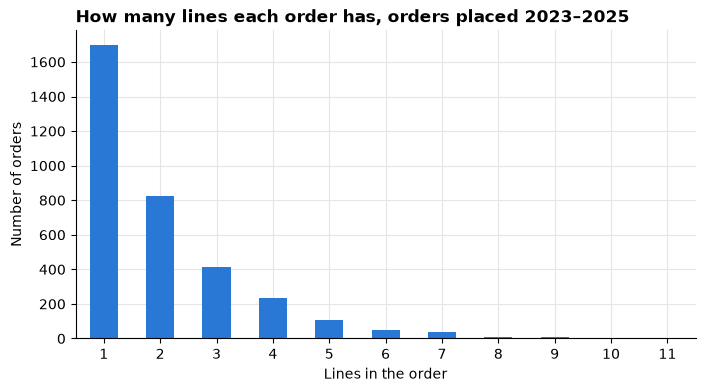

In [14]:
lines_per_order = df.groupby("order_id").size().value_counts().sort_index()
lines_per_order.plot(kind="bar", title="How many lines each order has, orders placed 2023–2025")
plt.xlabel("Lines in the order")
plt.ylabel("Number of orders")
plt.xticks(rotation=0)
plt.show()

Many orders have one line, but plenty have several. That is why `len(df)` overstates the number of orders.

---

## Part 6: What the returns flag means

`returned_order_flag` is `1` when an order is on the source's **returns list**. Be careful with what it does **not** tell you:

- It has **no** return date, quantity or refund amount.
- A `0` means **not on the list**. It does not prove the order was never returned.
- The flag repeats on **every line** of a listed order.

The order you looked at in Part 5 is on the list. See how the flag repeats:

In [15]:
df[df["order_id"] == "US-2023-100762"][["row_id", "order_id", "returned_order_flag"]]

,row_id,order_id,returned_order_flag
1684,1685,US-2023-100762,1
1688,1689,US-2023-100762,1
1690,1691,US-2023-100762,1
1691,1692,US-2023-100762,1


Now compare two ways of counting:

In [16]:
flagged = df[df["returned_order_flag"] == 1]
print("Sum of the flag (counts LINES):        ", df["returned_order_flag"].sum())
print("Distinct orders on the returns list:   ", flagged["order_id"].nunique())

Sum of the flag (counts LINES):         511
Distinct orders on the returns list:    191


> **A common mistake**
>
> Adding up `returned_order_flag` counts **lines** of listed orders, not orders. To count orders on the returns list, filter to flag 1 and use `nunique()` on `order_id`, as in the second line of the output above.

Say "orders on the returns list", not "returned orders" or "return rate": the list tells us membership only.

---

## Part 7: Check one order by hand

Pick one order with several lines and add it up yourself.

1. Show each line's `sales` and `profit`.
2. Add the lines up on paper or with a calculator.
3. Compare with what pandas says.

In [17]:
one_order = df[df["order_id"] == "US-2023-100762"]
one_order[["row_id", "product_id", "sales", "profit"]]

,row_id,product_id,sales,profit
1684,1685,OFF-AR-10000380,151.92,45.58
1688,1689,OFF-LA-10003930,196.62,96.34
1690,1691,OFF-PA-10001815,144.12,69.18
1691,1692,OFF-PA-10004082,15.96,7.98


In [18]:
print("pandas total sales: ", round(one_order["sales"].sum(), 2))
print("pandas total profit:", round(one_order["profit"].sum(), 2))

pandas total sales:  508.62
pandas total profit: 219.08


Do your hand totals match the output above? Small differences in the last digit come from rounding.

> **Your turn:** change the code in the next cell and run it again.

In [19]:
# Hand-check a different order.
# 1. Replace the order ID with another one that has several lines,
#    for example one you saw in df.head(20).
# 2. Add up the lines yourself, then compare with the totals printed below.
one_order = df[df["order_id"] == "US-2023-100762"]
print(one_order[["row_id", "product_id", "sales", "profit"]])
print("pandas total sales: ", round(one_order["sales"].sum(), 2))
print("pandas total profit:", round(one_order["profit"].sum(), 2))

      row_id       product_id  sales  profit
1684    1685  OFF-AR-10000380 151.92   45.58
1688    1689  OFF-LA-10003930 196.62   96.34
1690    1691  OFF-PA-10001815 144.12   69.18
1691    1692  OFF-PA-10004082  15.96    7.98
pandas total sales:  508.62
pandas total profit: 219.08


Record the order ID, your hand total and the pandas total in your log.

---

## Part 8: Keep a preparation log

Write down every change made to how the data is read or shaped, even small ones. You can keep the log in pandas too:

In [20]:
prep_log = pd.DataFrame([
    {"change": "Kept orders placed 2023-01-01 to 2025-12-31",
     "why": "Fixed course period", "checked": "Min and max order_date"},
    {"change": "Counted orders with order_id.nunique()",
     "why": "Rows are order lines", "checked": "Compared with len(df); hand-checked one order"},
])
prep_log

,change,why,checked
0,Kept orders placed 2023-01-01 to 2025-12-31,Fixed course period,Min and max order_date
1,Counted orders with order_id.nunique(),Rows are order lines,Compared with len(df); hand-checked one order


> **Your turn:** change the code in the next cell and run it again.

In [21]:
# Add one more row to the log: the change you think matters most from Part 2.
# Fill in the three texts, then run the cell.
prep_log = pd.concat([prep_log, pd.DataFrame([
    {"change": "...", "why": "...", "checked": "..."},
])], ignore_index=True)
prep_log

,change,why,checked
0,Kept orders placed 2023-01-01 to 2025-12-31,Fixed course period,Min and max order_date
1,Counted orders with order_id.nunique(),Rows are order lines,Compared with len(df); hand-checked one order
2,...,...,...


---

## Part 9: Segment versus category

For each segment: number of rows, number of distinct orders and total sales. `agg` computes several summaries at once.

In [22]:
by_segment = df.groupby("segment").agg(
    rows=("row_id", "count"),
    orders=("order_id", "nunique"),
    sales=("sales", "sum"),
)
by_segment.reset_index()

,segment,rows,orders,sales
0,Consumer,3586,1738,"835,747.86"
1,Corporate,2084,1044,"467,562.02"
2,Home Office,1145,606,"277,656.95"


In [23]:
print("Sum of segment order counts:", by_segment["orders"].sum())
print("Overall distinct orders:    ", df["order_id"].nunique())

Sum of segment order counts: 3388
Overall distinct orders:     3388


The same table for product category:

In [24]:
by_category = df.groupby("category").agg(
    rows=("row_id", "count"),
    orders=("order_id", "nunique"),
    sales=("sales", "sum"),
)
by_category.reset_index()

,category,rows,orders,sales
0,Furniture,1488,1235,"535,434.83"
1,Office Supplies,4093,2516,"478,057.88"
2,Technology,1234,1028,"567,474.11"


In [25]:
print("Sum of category order counts:", by_category["orders"].sum())
print("Overall distinct orders:     ", df["order_id"].nunique())

Sum of category order counts: 4779
Overall distinct orders:      3388


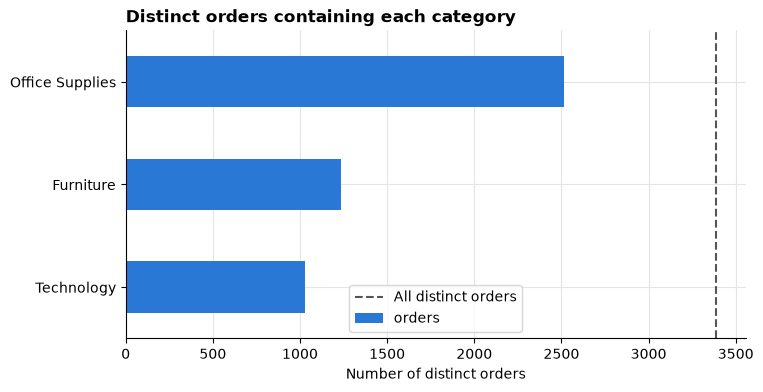

In [26]:
by_category["orders"].sort_values().plot(kind="barh", title="Distinct orders containing each category")
plt.axvline(df["order_id"].nunique(), color="#555555", linestyle="--", label="All distinct orders")
plt.xlabel("Number of distinct orders")
plt.ylabel("")
plt.legend()
plt.show()

Compare the two pairs of numbers in the outputs above.

- In this table every order has exactly one segment, so the segment counts add up to the overall total.
- One order can contain products from **several categories**. That order is counted once in each category it touches, so the category counts add up to **more** than the overall total.

> **Distinct counts do not always add up**
>
> Sales and Profit can be added across groups. Distinct order counts can only be added when every order belongs to exactly one group. Always recount distinct orders at the level you display.

> **Your turn:** change the code in the next cell and run it again.

In [27]:
# Try another grouping.
# 1. Change "category" to "region", then to "sub_category".
# 2. For each, compare the sum of order counts with the overall distinct orders.
#    Which one behaves like segment, and which like category?
by_group = df.groupby("category").agg(
    rows=("row_id", "count"),
    orders=("order_id", "nunique"),
)
print(by_group)
print("Sum of order counts:    ", by_group["orders"].sum())
print("Overall distinct orders:", df["order_id"].nunique())

                 rows  orders
category                     
Furniture        1488    1235
Office Supplies  4093    2516
Technology       1234    1028
Sum of order counts:     4779
Overall distinct orders: 3388


---

## Part 10: Debugging challenge

A colleague sends this code and summary:

> *"We had `len(df)` orders, and `df["returned_order_flag"].sum()` of them were returned."*

> **Your turn:** change the code in the next cell and run it again.

In [28]:
# The colleague's code. It runs, but both numbers answer the wrong question.
# 1. Find the two mistakes.
# 2. Fix each line so it counts ORDERS, not lines.
# 3. Rewrite the sentence using careful wording about the returns list.
orders = len(df)
returned = df["returned_order_flag"].sum()
print("We had", orders, "orders, and", returned, "of them were returned.")

We had 6815 orders, and 511 of them were returned.


> **How would you check your fix?**
>
> Compare your corrected numbers with the outputs in Parts 5 and 6. Then pick one listed order and confirm it is counted once, not once per line.

---

## Exit ticket

1. Your grain statement.
2. Why rows and orders differ in this table.
3. One thing the returns flag cannot tell you.
4. One change `load_orders()` makes to the original file, and why.

## After the lesson

- Finish the grouping exercise in Part 9 and your hand-checked order.
- Complete your preparation log and quality checklist.
- Previous: [Lesson 1](01_decision_to_evidence.md). Next: [Lesson 3](03_segment_comparison.md), comparing segments with Sales, Profit and average order value.